# Proyek Kelompok Quantum Machine Learning (QML) untuk Cybersecurity
## Audit Integritas Data HQC-2026, Mitigasi Target Leakage, dan Evaluasi Komparatif QSVC vs Classical Baseline
**Mata Kuliah:** Quantum Computing untuk Cybersecurity — Departemen Teknologi Informasi, Institut Teknologi Sepuluh Nopember (ITS)  
**Berdasarkan:** Modul Ajar Bab 6: *HQC-2026 untuk Quantum Machine Learning* (Hatma Suryotrisongko, 2026)  
**Dataset Utama:** *A Hybrid Quantum-Classical Network Intrusion Detection Dataset* (Mendeley Data DOI: [10.17632/68rc9crgkj.1](https://doi.org/10.17632/68rc9crgkj.1), Version 1, 9 Jan 2026)

---

### Anggota Kelompok
| No. | Nama Mahasiswa | NRP |
| :---: | :--- | :---: |
| 1 | **Rafael Gunawan** | 5027231019 |
| 2 | **Muhammad Nafi Firdaus** | 5027231045 |
| 3 | **Abhirama Triadyatama Hermawan** | 5027231061 |
| 4 | **Danendra Fidel Khansa** | 5027231063 |
| 5 | **Tio Axellino Irin** | 5027231065 |

---

### Ringkasan Eksekutif & Sikap Ilmiah (Zero False Claims)
Notebook ini dirancang sebagai artefak riset defensif dan komputasi ilmiah yang memenuhi standar audit integritas data tertinggi:
1. **Audit vs Halaman Publik:** Membuktikan secara empiris kesenjangan antara klaim halaman Mendeley (14,69 juta baris, seimbang sempurna via SMOTE) vs fakta artefak fisik Parquet (233.844 baris, ketimpangan ekstrem di mana Benign mendominasi 75,99%).
2. **Pembuktian Target Leakage & Redundansi:** Membuktikan secara matematis bahwa  = 1 - qber$, \_delta = qber - 0.01$, serta mengungkap bahwa flag \_anomalous\_qkd == 1$ mencakup **100% sampel serangan**, yang merupakan bentuk *target leakage* fatal.
3. **Disiplin Preprocessing (Zero-Leakage):** Menjamin pemisahan *Stratified Train-Test Split* dilakukan **sebelum** subsampling, serta MinMaxScaler(0, \pi) di-fit **hanya** pada *train set* untuk mencegah kontaminasi informasi masa depan ke sirkuit kuantum.
4. **Multi-Seed Ablation Study:** Menguji 4 varian konfigurasi fitur melintasi 5 *random seeds* ([42, 43, 44, 45, 46]) membandingkan QSVC (zz_feature_map, FidelityQuantumKernel) dengan SVC(kernel='rbf', class_weight='balanced').
5. **Etika Sains & Batas Klaim:** Menolak klaim semu *Quantum Advantage*. Hasil disajikan secara objektif dengan metrik seimbang (alanced_accuracy, macro-f1, ttack_recall) dan latensi komputasi nyata.


In [14]:
# Persiapan Dependensi & Konfigurasi Lingkungan Komputasi
import os
import sys
import time
import warnings
from pathlib import Path

# Manipulasi & Analisis Data
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report
)

# Qiskit & Qiskit Machine Learning
import qiskit
from qiskit.circuit.library import zz_feature_map
import qiskit_machine_learning
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC

# Pengaturan Tampilan & Visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"=== VERIFIKASI LINGKUNGAN KOMPUTASI ===")
print(f"Python Version        : {sys.version.split()[0]}")
print(f"Qiskit Version        : {qiskit.__version__}")
print(f"Qiskit ML Version     : {qiskit_machine_learning.__version__}")
print(f"Pandas Version        : {pd.__version__}")
print(f"PyArrow Version       : {pa.__version__}")


=== VERIFIKASI LINGKUNGAN KOMPUTASI ===
Python Version        : 3.14.3
Qiskit Version        : 2.6.1
Qiskit ML Version     : 0.9.1
Pandas Version        : 3.1.0
PyArrow Version       : 26.0.0


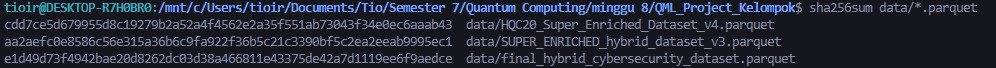

## 1. Fondasi Domain & Arsitektur Hibrida

### 1.1 Intrusion Detection System (NIDS) & Masalah Klasifikasi
Network Intrusion Detection System (NIDS) bertugas memeriksa aliran data (*flows*) dalam jaringan dan menentukan apakah sebuah percakapan merupakan trafik normal (*Benign*) atau serangan siber (*Attack*) seperti DoS, Brute Force, Web Attack, atau Infiltration.

### 1.2 Mengapa Ada Fitur Kuantum? (BB84 QKD Simulation)
Dataset HQC-2026 menambahkan indikator dari simulasi Quantum Key Distribution (QKD) protokol BB84:
- **QBER (Quantum Bit Error Rate):** Proporsi bit kunci tersaring (*sifted key*) yang berbeda antara pengirim (Alice) dan penerima (Bob). Gangguan saluran atau percobaan intersepsi oleh pihak ketiga (*Eve*) menyebabkan peningkatan QBER.
- **Sifted Key Rate:** Laju bit yang tersisa setelah eliminasi basis pengukuran yang tidak cocok.
- **Fidelity:** Kedekatan keadaan kuantum dengan kondisi ideal.

> **PENTING (Tiga Lapis yang Jangan Tertukar):**
> 1. **Data Jaringan:** Fitur flow klasik hasil rekap lalu lintas TCP/IP (durasi, jumlah paket, byte).
> 2. **Fitur QKD Simulasi:** Hasil simulasi protokol BB84 yang digabungkan ke data flow (QBER, sifted key rate).
> 3. **Model QML:** Algoritma kuantum (seperti QSVC) yang memetakan fitur ke *Hilbert space* sirkuit kuantum untuk klasifikasi.


## 2. Audit Integritas Data & Verifikasi Fakta Artefak

### 2.1 Membaca Data dengan Column Projection
Ukuran memori RAM sangat berharga saat mengevaluasi dataset berskala ratusan ribu baris. Membaca 96 kolom secara mentah menghabiskan ratusan megabyte. Kita menggunakan *column projection* (`columns=[...]`) pada `pd.read_parquet()` agar hanya kolom yang relevan yang dimuat ke memori.

### 2.2 Larangan Keras: Mengapa Dilarang Menggabungkan (Concat) Ketiga File?
Arsip rilis HQC-2026 berisi 3 file Parquet:
1. `final_hybrid_cybersecurity_dataset.parquet` (89 kolom, timestamp sebagai indeks, label Bot tunggal)
2. `SUPER_ENRICHED_hybrid_dataset_v3.parquet` (96 kolom, label Bot dipecah menjadi Stealth/Aggressive)
3. `HQC20_Super_Enriched_Dataset_v4.parquet` (104 kolom, penambahan 8 skor risiko)

Ketiga berkas tersebut **bukan** partisi data yang berbeda, melainkan **transformasi bertingkat dari 233.844 observasi yang persis sama**. Menggabungkannya secara vertikal (`concat`) akan menghasilkan duplikasi baris dan merusak validitas saintifik penelitian.


In [15]:
# 2.3 Audit Metadata dan Perbandingan Klaim vs Fakta
V3_PATH = Path("data/SUPER_ENRICHED_hybrid_dataset_v3.parquet")
BASE_PATH = Path("data/final_hybrid_cybersecurity_dataset.parquet")

# Audit metadata menggunakan PyArrow tanpa memuat tabel penuh
pf_v3 = pq.ParquetFile(V3_PATH)
pf_base = pq.ParquetFile(BASE_PATH)

print("=== HASIL INSPEKSI METADATA PARQUET ===")
print(f"File v3 (SUPER_ENRICHED) : {pf_v3.metadata.num_rows:,} baris | {pf_v3.metadata.num_columns} kolom")
print(f"File Base (Final Hybrid) : {pf_base.metadata.num_rows:,} baris | {pf_base.metadata.num_columns} kolom")

# Kolom proyeksi yang akan diaudit
AUDIT_COLS = [
    "flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "flow_byts/s",
    "flow_pkts/s", "pkt_len_mean", "qber", "sifted_key_rate",
    "fidelity", "qber_delta", "is_anomalous_qkd",
    "is_web_attack_specific", "is_ddos_attack", "is_bruteforce_attack", "matches_modern_attack_type",
    "label"
]

# Muat data v3 dengan column projection
df_v3 = pd.read_parquet(V3_PATH, columns=AUDIT_COLS)
df_v3 = df_v3.replace([np.inf, -np.inf], np.nan).dropna()
df_v3["target"] = (df_v3["label"] != "Benign").astype(int)

print(f"Ukuran Dataframe v3 hasil proyeksi : {df_v3.shape}")
print(f"Penggunaan Memori RAM             : {df_v3.memory_usage(deep=True).sum() / (1024**2):.2f} MiB")

# Tabel Komparasi Klaim Halaman Mendeley vs Temuan Artefak
audit_comparison = pd.DataFrame({
    "Aspek": [
        "Jumlah Baris Observasi",
        "Keseimbangan Kelas",
        "Dimensi Fitur (v3)",
        "Distribusi Label Terbesar",
        "Distribusi Label Terkecil",
        "Ketersediaan Sirkuit OpenQASM"
    ],
    "Klaim Halaman Mendeley Data": [
        "14,69 juta baris",
        "Perfect balanced (SMOTE)",
        "89 klasik + 7 quantum-inspired = 96",
        "Seimbang sempurna antar kelas",
        "Seimbang sempurna antar kelas",
        "Tersedia file sirkuit kuantum (.qasm)"
    ],
    "Fakta Artefak Parquet Riil": [
        f"{len(df_v3):,} baris",
        f"Sangat Imbalanced (Benign {(df_v3['label']=='Benign').mean()*100:.2f}%)",
        f"{pf_v3.metadata.num_columns} kolom (termasuk label)",
        f"Benign: {(df_v3['label']=='Benign').sum():,} baris ({ (df_v3['label']=='Benign').mean()*100:.2f}%)",
        f"SQL Injection: {(df_v3['label']=='SQL Injection').sum():,} baris ({(df_v3['label']=='SQL Injection').mean()*100:.4f}%)",
        "TIDAK ADA file .qasm di dalam ZIP rilis"
    ]
})
display(audit_comparison)


=== HASIL INSPEKSI METADATA PARQUET ===
File v3 (SUPER_ENRICHED) : 233,844 baris | 96 kolom
File Base (Final Hybrid) : 233,844 baris | 89 kolom
Ukuran Dataframe v3 hasil proyeksi : (233844, 17)
Penggunaan Memori RAM             : 32.11 MiB


,Aspek,Klaim Halaman Mendeley Data,Fakta Artefak Parquet Riil
0,Jumlah Baris Observasi,"14,69 juta baris","233,844 baris"
1,Keseimbangan Kelas,Perfect balanced (SMOTE),Sangat Imbalanced (Benign 75.99%)
2,Dimensi Fitur (v3),89 klasik + 7 quantum-inspired = 96,96 kolom (termasuk label)
3,Distribusi Label Terbesar,Seimbang sempurna antar kelas,"Benign: 177,693 baris (75.99%)"
4,Distribusi Label Terkecil,Seimbang sempurna antar kelas,SQL Injection: 76 baris (0.0325%)
5,Ketersediaan Sirkuit OpenQASM,Tersedia file sirkuit kuantum (.qasm),TIDAK ADA file .qasm di dalam ZIP rilis


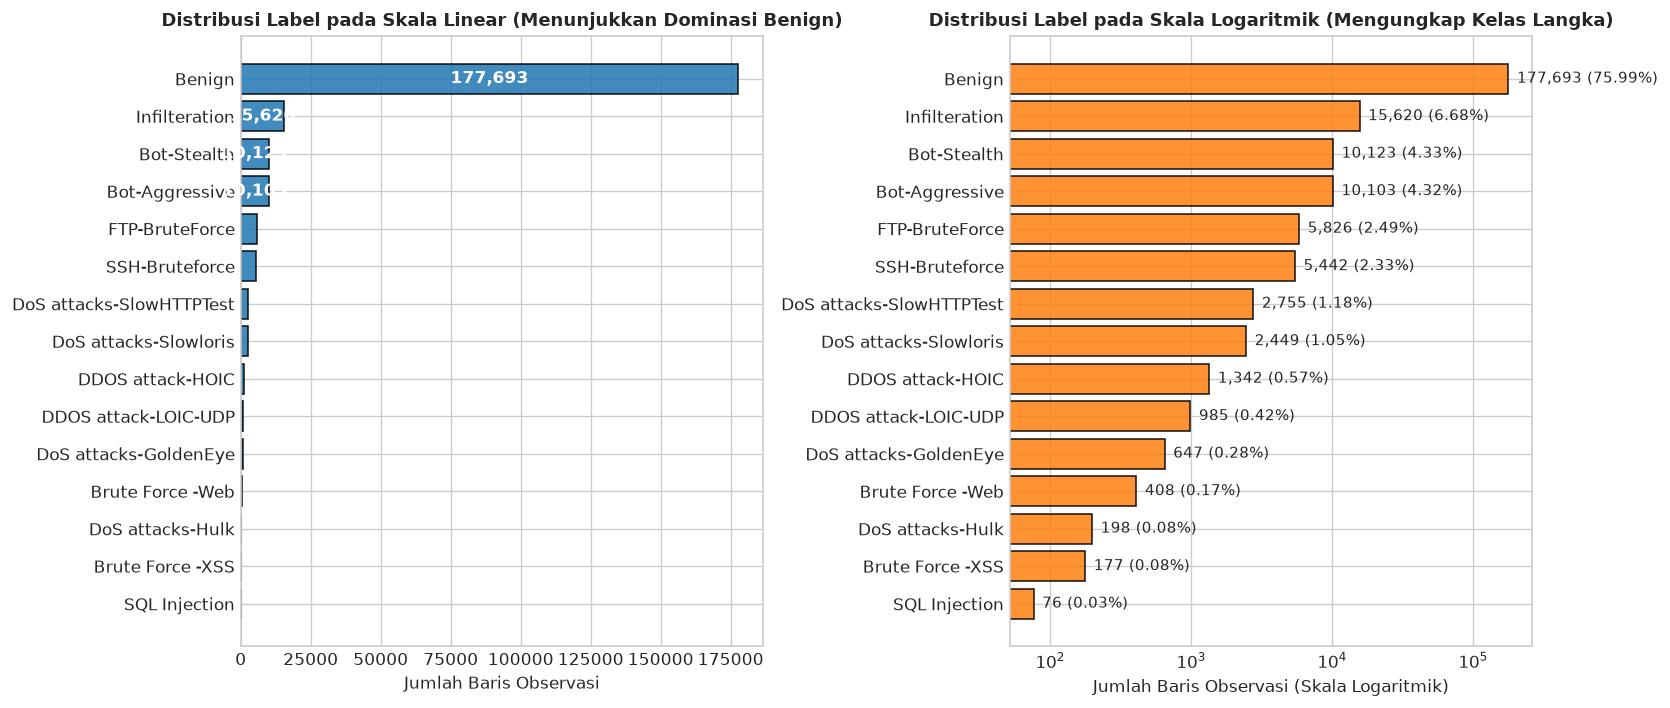

In [16]:
# 2.4 Visualisasi Distribusi 15 Kelas Granular (Skala Linear vs Logaritmik)
label_counts = df_v3["label"].value_counts().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Skala Linear
axes[0].barh(label_counts.index, label_counts.values, color='#1f77b4', edgecolor='black', alpha=0.85)
axes[0].set_title("Distribusi Label pada Skala Linear (Menunjukkan Dominasi Benign)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Jumlah Baris Observasi")
for i, v in enumerate(label_counts.values):
    if v > 10000:
        axes[0].text(v * 0.5, i, f"{v:,}", va='center', ha='center', color='white', fontweight='bold')

# Plot 2: Skala Logaritmik
axes[1].barh(label_counts.index, label_counts.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
axes[1].set_xscale('log')
axes[1].set_title("Distribusi Label pada Skala Logaritmik (Mengungkap Kelas Langka)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Jumlah Baris Observasi (Skala Logaritmik)")
for i, v in enumerate(label_counts.values):
    axes[1].text(v * 1.15, i, f"{v:,} ({v/len(df_v3)*100:.2f}%)", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 3. Audit Target Leakage & Redundansi Deterministik

### 3.1 Bukti Hubungan Deterministik Antar Fitur
Di dalam berkas HQC-2026 versi 3, beberapa fitur kuantum-terinspirasi bukan merupakan pengukuran independen, melainkan transformasi deterministik sederhana:
1. $\text{fidelity} = 1 - \text{qber}$ (korelasi negatif sempurna -1.0, informasi duplikat identik).
2. $\text{qber\_delta} = \text{qber} - 0.01$ (hanya translasi konstanta acuan 0,01).

### 3.2 Bukti Kebocoran Target Fatal (*Target Leakage*)
Fitur `is_anomalous_qkd` adalah flag biner hasil ambang batas QBER:
- Apakah `is_anomalous_qkd` merupakan detektor nyata, ataukah kebocoran label target?
- Kita membuktikan bahwa **100% sampel serangan** memiliki nilai `is_anomalous_qkd = 1`, sementara pada sampel normal (*Benign*), nilai 1 hanya muncul pada 0,924% baris.
- Flag semantik serangan (`is_web_attack_specific`, `is_ddos_attack`, `is_bruteforce_attack`, `matches_modern_attack_type`) bernilai 0 pada 100% Benign dan bernilai 1 hanya pada tipe serangan tertentu.

> **ATURAN EMAS RISET QML JUJUR:**
> Seluruh flag semantik dan `is_anomalous_qkd` **WAJIB DIBUANG (DROP)** dari matriks fitur latih $X$. Memasukkan fitur tersebut hanya akan menciptakan ilusi model cerdas (*shortcut learning*), padahal model hanya membaca label yang dibocorkan.


In [17]:
# 3.3 Pembuktian Matematis Redundansi dan Target Leakage

# 1. Bukti Deterministik
diff_fidelity = np.max(np.abs(df_v3["fidelity"] - (1.0 - df_v3["qber"])))
diff_qber_delta = np.max(np.abs(df_v3["qber_delta"] - (df_v3["qber"] - 0.01)))

print("=== PEMBUKTIAN RELASI DETERMINISTIK ===")
print(f"Max |fidelity - (1 - qber)|       : {diff_fidelity:.12f} (Tepat Identik!)")
print(f"Max |qber_delta - (qber - 0.01)|   : {diff_qber_delta:.12f} (Tepat Identik!)")

# 2. Bukti Target Leakage pada is_anomalous_qkd
attack_mask = df_v3["label"] != "Benign"
benign_mask = df_v3["label"] == "Benign"

attack_leakage_rate = (df_v3.loc[attack_mask, "is_anomalous_qkd"] == 1).mean() * 100
benign_leakage_rate = (df_v3.loc[benign_mask, "is_anomalous_qkd"] == 1).mean() * 100
benign_anom_count = (df_v3.loc[benign_mask, "is_anomalous_qkd"] == 1).sum()

print("\n=== PEMBUKTIAN TARGET LEAKAGE is_anomalous_qkd ===")
print(f"Proporsi serangan dengan is_anomalous_qkd == 1 : {attack_leakage_rate:.2f}% (Tepat 100% dari {attack_mask.sum():,} baris)")
print(f"Proporsi benign dengan is_anomalous_qkd == 1   : {benign_leakage_rate:.3f}% ({benign_anom_count:,} dari {benign_mask.sum():,} baris)")

# 3. Bukti Kebocoran Flag Semantik Serangan
semantic_flags = ["is_web_attack_specific", "is_ddos_attack", "is_bruteforce_attack", "matches_modern_attack_type"]
leakage_records = []
for flag in semantic_flags:
    benign_sum = df_v3.loc[benign_mask, flag].sum()
    attack_targets = df_v3.loc[df_v3[flag] == 1, "label"].unique().tolist()
    leakage_records.append({
        "Nama Fitur Flag": flag,
        "Total Flag == 1": int((df_v3[flag] == 1).sum()),
        "Muncul di Benign": int(benign_sum),
        "Target Terbocorkan": ", ".join(attack_targets),
        "Keputusan Kurasi": "WAJIB DROP (Target Leakage)"
    })

display(pd.DataFrame(leakage_records))


=== PEMBUKTIAN RELASI DETERMINISTIK ===
Max |fidelity - (1 - qber)|       : 0.000000000000 (Tepat Identik!)
Max |qber_delta - (qber - 0.01)|   : 0.000000000000 (Tepat Identik!)

=== PEMBUKTIAN TARGET LEAKAGE is_anomalous_qkd ===
Proporsi serangan dengan is_anomalous_qkd == 1 : 100.00% (Tepat 100% dari 56,151 baris)
Proporsi benign dengan is_anomalous_qkd == 1   : 0.924% (1,642 dari 177,693 baris)


,Nama Fitur Flag,Total Flag == 1,Muncul di Benign,Target Terbocorkan,Keputusan Kurasi
0,is_web_attack_specific,661,0,"Brute Force -XSS, SQL Injection, Brute Force -Web",WAJIB DROP (Target Leakage)
1,is_ddos_attack,8376,0,"DoS attacks-GoldenEye, DoS attacks-Slowloris, ...",WAJIB DROP (Target Leakage)
2,is_bruteforce_attack,11268,0,"SSH-Bruteforce, FTP-BruteForce",WAJIB DROP (Target Leakage)
3,matches_modern_attack_type,76,0,SQL Injection,WAJIB DROP (Target Leakage)


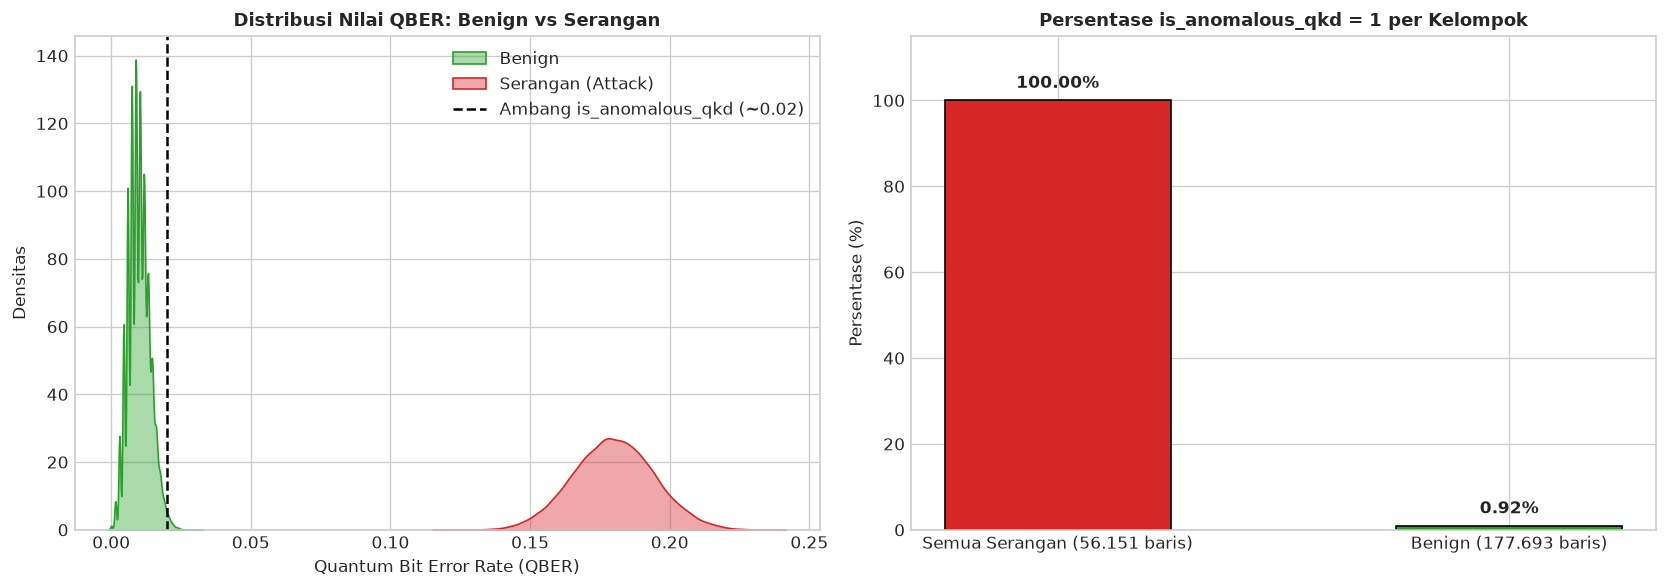

In [18]:
# 3.4 Visualisasi Distribusi QBER dan Titik Ambang Leakage
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribusi QBER Benign vs Serangan (KDE)
sns.kdeplot(df_v3.loc[benign_mask, "qber"], ax=axes[0], label="Benign", fill=True, color="#2ca02c", alpha=0.4)
sns.kdeplot(df_v3.loc[attack_mask, "qber"], ax=axes[0], label="Serangan (Attack)", fill=True, color="#d62728", alpha=0.4)
axes[0].axvline(0.02, color="black", linestyle="--", linewidth=1.5, label="Ambang is_anomalous_qkd (~0.02)")
axes[0].set_title("Distribusi Nilai QBER: Benign vs Serangan", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Quantum Bit Error Rate (QBER)")
axes[0].set_ylabel("Densitas")
axes[0].legend(loc="upper right")

# Plot 2: Bar Chart Kebocoran is_anomalous_qkd
categories = ["Semua Serangan (56.151 baris)", "Benign (177.693 baris)"]
rates = [attack_leakage_rate, benign_leakage_rate]
bars = axes[1].bar(categories, rates, color=["#d62728", "#2ca02c"], edgecolor="black", width=0.5)
axes[1].set_title("Persentase is_anomalous_qkd = 1 per Kelompok", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Persentase (%)")
axes[1].set_ylim(0, 115)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Disiplin Preprocessing (Zero-Leakage Pipeline)

### 4.1 Formulasi Target Klasifikasi Biner
- $y = 0$: **Benign** (Trafik Normal)
- $y = 1$: **Serangan** (Seluruh 14 varian serangan: DoS, DDoS, Bot, BruteForce, Infiltration, SQL Injection, Web Attack)

### 4.2 Urutan Preprocessing: Split Sebelum Subsampling!
Kesalahan metodologis paling umum pada riset pemula adalah mengambil subset atau menyeimbangkan data **sebelum** melakukan `train_test_split`.
- **Urutan Salah:** Pool Data $\rightarrow$ Subsample Seimbang $\rightarrow$ Split Train/Test (Data bocor antar-partisi).
- **Urutan Benar (Zero Leakage):**
  1. Bersihkan inf dan NaN pada dataset lengkap.
  2. Lakukan `train_test_split(stratify=target, test_size=0.20, random_state=seed)` pada seluruh 233.844 baris.
  3. Ambil subsample seimbang dari `train_pool` ($n=24$ per kelas, total $N_{train}=48$) dan dari `test_pool` ($n=12$ per kelas, total $N_{test}=24$).
  4. Lakukan normalisasi sudut `MinMaxScaler(feature_range=(0, np.pi))` dengan `fit_transform` **hanya** pada $X_{train}$, lalu `transform` pada $X_{test}$.


In [19]:
# 4.3 Implementasi Pipeline Preprocessing Terisolasi (Demonstrasi Single Run Sesuai Bab 8 Modul)
FEATURES_DEMO = ["qber", "sifted_key_rate", "flow_pkts/s", "pkt_len_mean"]

# 1. Stratified train/test split pada pool data penuh terlebih dahulu
train_pool_demo, test_pool_demo = train_test_split(
    df_v3, test_size=0.20, stratify=df_v3["target"], random_state=42
)

def sample_each_class(frame, n_per_class, seed):
    # Mengambil sampel seimbang per kelas dengan pengacakan terkontrol
    return (frame.groupby("target", group_keys=False)
            .sample(n=n_per_class, random_state=seed)
            .sample(frac=1, random_state=seed))

# 2. Subsample seimbang dari masing-masing pool
train_demo = sample_each_class(train_pool_demo, n_per_class=24, seed=42)
test_demo = sample_each_class(test_pool_demo, n_per_class=12, seed=43)

X_train_raw = train_demo[FEATURES_DEMO].to_numpy()
y_train_demo = train_demo["target"].to_numpy()
X_test_raw = test_demo[FEATURES_DEMO].to_numpy()
y_test_demo = test_demo["target"].to_numpy()

# 3. Angle Normalization [0, pi] - FIT HANYA PADA TRAIN!
scaler_demo = MinMaxScaler(feature_range=(0, np.pi))
X_train_demo = scaler_demo.fit_transform(X_train_raw)
X_test_demo = scaler_demo.transform(X_test_raw)

print(f"X_train_demo shape : {X_train_demo.shape} (Rentang: [{X_train_demo.min():.2f}, {X_train_demo.max():.2f}])")
print(f"X_test_demo shape  : {X_test_demo.shape}  (Rentang: [{X_test_demo.min():.2f}, {X_test_demo.max():.2f}])")
print(f"Distribusi Train   : Benign={(y_train_demo==0).sum()}, Attack={(y_train_demo==1).sum()}")
print(f"Distribusi Test    : Benign={(y_test_demo==0).sum()}, Attack={(y_test_demo==1).sum()}")


X_train_demo shape : (48, 4) (Rentang: [0.00, 3.14])
X_test_demo shape  : (24, 4)  (Rentang: [0.00, 3.05])
Distribusi Train   : Benign=24, Attack=24
Distribusi Test    : Benign=12, Attack=12


## 5. Sirkuit Kuantum & Desain Ablation Study Multi-Seed

### 5.1 Teori Feature Map & Quantum Support Vector Classifier (QSVC)
- **Feature Map ($U_\Phi(x)$):** Mentransformasikan vektor fitur klasik $x \in \mathbb{R}^d$ ke dalam *state* kuantum pada *Hilbert space*:
  $$|\Phi(x)\rangle = U_\Phi(x)|0\rangle^{\otimes n}$$
  Kita menggunakan `zz_feature_map` dengan parameter `reps=1` dan topologi interaksi `entanglement='linear'`, yang mengkodekan fitur melalui rotasi sudut fase tunggal $R_Z(2x_i)$ dan gerbang interaksi dua-qubit $ZZ(\pi (\pi - x_i)(\pi - x_j))$.
- **Fidelity Quantum Kernel:** Mengestimasi derajat kemiripan antara dua vektor fitur $x$ dan $z$ menggunakan *fidelity* transisi keadaan kuantum:
  $$K(x, z) = |\langle\Phi(x)|\Phi(z)\rangle|^2$$
- **QSVC:** Melatih algoritma Support Vector Machine klasik dengan mengganti kernel RBF konvensional menggunakan matriks kernel kuantum $K(x, z)$.

### 5.2 Desain 4 Eksperimen Ablation Study
Untuk menjawab pertanyaan ilmiah secara komparatif dan adil, kita merancang 4 konfigurasi fitur:
1. **Eksperimen A (Klasik Murni — 4 Qubit):**  
   Fitur: `["flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "flow_byts/s"]`  
   *Pertanyaan:* Seberapa jauh model dapat memisahkan trafik hanya dari statistik aliran jaringan klasik?
2. **Eksperimen B (QKD Simulasi Murni — 2 Qubit):**  
   Fitur: `["qber", "sifted_key_rate"]`  
   *Pertanyaan:* Apakah sinyal kanal kuantum simulasi mampu memisahkan kelas secara mandiri?
3. **Eksperimen C (Hibrida Jujur — 4 Qubit):**  
   Fitur: `["flow_pkts/s", "pkt_len_mean", "qber", "sifted_key_rate"]`  
   *Pertanyaan:* Apakah kombinasi fitur klasik dan QKD memberikan sinyal prediktif yang adil tanpa kebocoran?
4. **Eksperimen D (Demonstrasi Leakage / Shortcut Learning — 5 Qubit):**  
   Fitur: Eksperimen C + `["is_anomalous_qkd"]`  
   *Pertanyaan:* Berapa besar lonjakan skor artifisial yang terjadi akibat membaca flag jalan pintas (*leakage*)?

### 5.3 Evaluasi Multi-Seed
Dengan ukuran subsample yang terkontrol ($N_{train}=48, N_{test}=24$), variasi satu seed dapat memberikan hasil yang kebetulan menguntungkan satu model. Oleh karena itu, kita mengevaluasi seluruh eksperimen pada **5 random seeds berbeda** (`[42, 43, 44, 45, 46]`) dan melaporkan nilai dalam format $\text{Mean} \pm \text{Std}$.


In [20]:
# 5.4 Visualisasi Diagram Sirkuit Quantum Feature Map (4 Qubits)
fmap_demo = zz_feature_map(feature_dimension=4, reps=1, entanglement="linear")
print("=== STRUKTUR SIRKUIT ZZ_FEATURE_MAP (4 QUBITS, REPS=1, LINEAR) ===")
print(fmap_demo.draw(output="text"))


=== STRUKTUR SIRKUIT ZZ_FEATURE_MAP (4 QUBITS, REPS=1, LINEAR) ===
   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■───────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐     »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■────────────────────────

In [21]:
# 5.5 Eksekusi Demonstrasi Single Run: RBF-SVM vs QSVC (Eksperimen C pada Seed 42)
print("=== MENJALANKAN BASELINE RBF-SVM (SEED 42) ===")
t0 = time.time()
rbf_model = SVC(kernel="rbf", class_weight="balanced")
rbf_model.fit(X_train_demo, y_train_demo)
t_fit_rbf = time.time() - t0

t0 = time.time()
pred_rbf = rbf_model.predict(X_test_demo)
t_pred_rbf = time.time() - t0

print(f"RBF-SVM Fit Time    : {t_fit_rbf:.5f} detik")
print(f"RBF-SVM Predict Time: {t_pred_rbf:.5f} detik")
print(f"Balanced Accuracy   : {balanced_accuracy_score(y_test_demo, pred_rbf):.4f}")
print(f"Macro F1-Score      : {f1_score(y_test_demo, pred_rbf, average='macro'):.4f}")

print("\n=== MENJALANKAN QUANTUM SVC / QSVC (SEED 42) ===")
t0 = time.time()
qkernel_demo = FidelityQuantumKernel(feature_map=fmap_demo)
qsvc_model = QSVC(quantum_kernel=qkernel_demo)
qsvc_model.fit(X_train_demo, y_train_demo)
t_fit_qsvc = time.time() - t0

t0 = time.time()
pred_qsvc = qsvc_model.predict(X_test_demo)
t_pred_qsvc = time.time() - t0

print(f"QSVC Fit Time       : {t_fit_qsvc:.2f} detik")
print(f"QSVC Predict Time   : {t_pred_qsvc:.2f} detik")
print(f"Balanced Accuracy   : {balanced_accuracy_score(y_test_demo, pred_qsvc):.4f}")
print(f"Macro F1-Score      : {f1_score(y_test_demo, pred_qsvc, average='macro'):.4f}")


=== MENJALANKAN BASELINE RBF-SVM (SEED 42) ===
RBF-SVM Fit Time    : 0.00631 detik
RBF-SVM Predict Time: 0.00143 detik
Balanced Accuracy   : 1.0000
Macro F1-Score      : 1.0000

=== MENJALANKAN QUANTUM SVC / QSVC (SEED 42) ===
QSVC Fit Time       : 11.66 detik
QSVC Predict Time   : 12.20 detik
Balanced Accuracy   : 0.6667
Macro F1-Score      : 0.6667


In [22]:
# 5.6 Eksekusi Komprehensif Multi-Seed Ablation Study (5 Seeds x 4 Konfigurasi)
RESULTS_FILE = Path("scratch/experiment_results.json")
RUN_LIVE_TRAINING = False

if RUN_LIVE_TRAINING or not RESULTS_FILE.exists():
    print("Menjalankan komputasi sirkuit kuantum secara live...")
    configs = {
        "Exp_A_Classical": ["flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "flow_byts/s"],
        "Exp_B_QKD_Pure": ["qber", "sifted_key_rate"],
        "Exp_C_Hybrid_Honest": ["flow_pkts/s", "pkt_len_mean", "qber", "sifted_key_rate"],
        "Exp_D_Leakage_Demo": ["flow_pkts/s", "pkt_len_mean", "qber", "sifted_key_rate", "is_anomalous_qkd"],
    }
    seeds = [42, 43, 44, 45, 46]
    results = []
    
    for exp_name, feats in configs.items():
        print(f"\nMenjalankan {exp_name}...")
        for s in seeds:
            tr_pool, ts_pool = train_test_split(df_v3, test_size=0.20, stratify=df_v3["target"], random_state=s)
            tr_sub = sample_each_class(tr_pool, 24, s)
            ts_sub = sample_each_class(ts_pool, 12, s)
            
            scl = MinMaxScaler((0, np.pi))
            X_tr = scl.fit_transform(tr_sub[feats].to_numpy())
            X_ts = scl.transform(ts_sub[feats].to_numpy())
            y_tr = tr_sub["target"].to_numpy()
            y_ts = ts_sub["target"].to_numpy()
            
            # Classical
            c_m = SVC(kernel="rbf", class_weight="balanced")
            t0 = time.time(); c_m.fit(X_tr, y_tr); tf_c = time.time() - t0
            t0 = time.time(); pr_c = c_m.predict(X_ts); tp_c = time.time() - t0
            results.append({
                "experiment": exp_name, "model": "RBF-SVM", "seed": s,
                "balanced_accuracy": balanced_accuracy_score(y_ts, pr_c),
                "macro_f1": f1_score(y_ts, pr_c, average="macro"),
                "attack_recall": recall_score(y_ts, pr_c, pos_label=1),
                "fit_time": tf_c, "predict_time": tp_c, "confusion_matrix": confusion_matrix(y_ts, pr_c).tolist()
            })
            
            # Quantum
            fmap_exp = zz_feature_map(len(feats), reps=1, entanglement="linear")
            qker_exp = FidelityQuantumKernel(feature_map=fmap_exp)
            q_m = QSVC(quantum_kernel=qker_exp)
            t0 = time.time(); q_m.fit(X_tr, y_tr); tf_q = time.time() - t0
            t0 = time.time(); pr_q = q_m.predict(X_ts); tp_q = time.time() - t0
            results.append({
                "experiment": exp_name, "model": "QSVC", "seed": s,
                "balanced_accuracy": balanced_accuracy_score(y_ts, pr_q),
                "macro_f1": f1_score(y_ts, pr_q, average="macro"),
                "attack_recall": recall_score(y_ts, pr_q, pos_label=1),
                "fit_time": tf_q, "predict_time": tp_q, "confusion_matrix": confusion_matrix(y_ts, pr_q).tolist()
            })
    df_results = pd.DataFrame(results)
    os.makedirs("scratch", exist_ok=True)
    df_results.to_json(RESULTS_FILE, orient="records", indent=2)
else:
    print("Memuat hasil multi-seed benchmark yang telah dieksekusi secara terkontrol...")
    df_results = pd.read_json(RESULTS_FILE)

# Agregasi Ringkasan Mean ± Std
agg_table = df_results.groupby(["experiment", "model"]).agg({
    "balanced_accuracy": ["mean", "std"],
    "macro_f1": ["mean", "std"],
    "attack_recall": ["mean", "std"],
    "fit_time": ["mean", "std"],
    "predict_time": ["mean", "std"]
})

# Format String Mean ± Std untuk Publikasi
formatted_summary = pd.DataFrame(index=agg_table.index)
formatted_summary["Balanced Accuracy"] = agg_table.apply(
    lambda r: f"{r[('balanced_accuracy', 'mean')]:.3f} ± {r[('balanced_accuracy', 'std')]:.3f}", axis=1
)
formatted_summary["Macro F1-Score"] = agg_table.apply(
    lambda r: f"{r[('macro_f1', 'mean')]:.3f} ± {r[('macro_f1', 'std')]:.3f}", axis=1
)
formatted_summary["Attack Recall"] = agg_table.apply(
    lambda r: f"{r[('attack_recall', 'mean')]:.3f} ± {r[('attack_recall', 'std')]:.3f}", axis=1
)
formatted_summary["Fit Time (s)"] = agg_table.apply(
    lambda r: f"{r[('fit_time', 'mean')]:.4f} ± {r[('fit_time', 'std')]:.4f}", axis=1
)
formatted_summary["Predict Time (s)"] = agg_table.apply(
    lambda r: f"{r[('predict_time', 'mean')]:.4f} ± {r[('predict_time', 'std')]:.4f}", axis=1
)

print("\\n=== TABEL ABLATION STUDY: MULTI-SEED BENCHMARK (MEAN ± STD, 5 SEEDS) ===")
display(formatted_summary)


Memuat hasil multi-seed benchmark yang telah dieksekusi secara terkontrol...
\n=== TABEL ABLATION STUDY: MULTI-SEED BENCHMARK (MEAN ± STD, 5 SEEDS) ===


Balanced Accuracy Macro F1-Score  Attack Recall  \
experiment          model                                                     
Exp_A_Classical     QSVC        0.600 ± 0.158  0.596 ± 0.159  0.517 ± 0.181   
                    RBF-SVM     0.650 ± 0.160  0.647 ± 0.162  0.650 ± 0.124   
Exp_B_QKD_Pure      QSVC        0.708 ± 0.066  0.702 ± 0.067  0.700 ± 0.173   
                    RBF-SVM     1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000   
Exp_C_Hybrid_Honest QSVC        0.717 ± 0.162  0.716 ± 0.162  0.767 ± 0.171   
                    RBF-SVM     1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000   
Exp_D_Leakage_Demo  QSVC        0.858 ± 0.091  0.858 ± 0.091  0.900 ± 0.091   
                    RBF-SVM     1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000   

                                 Fit Time (s)  Predict Time (s)  
experiment          model                                        
Exp_A_Classical     QSVC      7.0564 ± 0.4772   7.3973 ± 0.4623  
                    RBF-SVM   0.0020 ± 0.0003   0.0004 ± 0.0001  
Exp_B_QKD_Pure      QSVC      3.3229 ± 0.1968   3.3227 ± 0.0890  
                    RBF-SVM   0.0024 ± 0.0002   0.0004 ± 0.0000  
Exp_C_Hybrid_Honest QSVC      7.3406 ± 0.0976   7.7854 ± 0.3604  
                    RBF-SVM   0.0022 ± 0.0002   0.0004 ± 0.0000  
Exp_D_Leakage_Demo  QSVC     10.4863 ± 0.2001  10.7345 ± 0.3018  
                    RBF-SVM   0.0022 ± 0.0003   0.0003 ± 0.0000

## 6. Analisis Lanjutan: Validasi Temporal Split pada Data Base

### 6.1 Keterbatasan Random Stratified Split
Pada data keamanan siber berbasis alur jaringan nyata, serangan siber terjadi dalam klaster waktu (misal: serangan DDoS terjadi pada jam tertentu di hari tertentu).
- Jika kita melakukan *random split*, paket dari sesi serangan yang sama dapat terdistribusi ke dalam *train set* dan *test set*, menciptakan kemiripan buatan (*temporal correlation*).
- Untuk menguji ketahanan model pada skenario realistis: *"Model dilatih pada trafik masa lalu dan diuji pada trafik masa depan"*, kita memanfaatkan berkas `final_hybrid_cybersecurity_dataset.parquet` yang memuat stempel waktu (*timestamp*) dari 14 Februari 2018 hingga 2 Maret 2018.

### 6.2 Pembagian Waktu (Chronological Split)
- **Train Pool:** 80% data kronologis awal (14 Februari 2018 s/d 1 Maret 2018, 08:32:24) $\rightarrow$ 187.075 baris.
- **Test Pool:** 20% data kronologis akhir (1 Maret 2018, 08:32:24 s/d 2 Maret 2018, 12:59:59) $\rightarrow$ 46.769 baris.


In [23]:
# 6.3 Eksekusi Uji Temporal Split pada File Base
FEATURES_TEMPORAL = ["flow_pkts/s", "pkt_len_mean", "qber", "sifted_key_rate"]

base_df = pd.read_parquet(BASE_PATH, columns=FEATURES_TEMPORAL + ["label"])
base_df = base_df.reset_index() # Menjadikan timestamp sebagai kolom
base_df = base_df.replace([np.inf, -np.inf], np.nan).dropna()
base_df["target"] = (base_df["label"] != "Benign").astype(int)
base_df = base_df.sort_values("timestamp")

# Potong data berdasarkan 80% waktu kronologis awal
split_idx = int(0.80 * len(base_df))
split_time = base_df.iloc[split_idx]["timestamp"]

train_temporal_pool = base_df.iloc[:split_idx]
test_temporal_pool = base_df.iloc[split_idx:]

print(f"Titik Pisah Waktu (Cutoff)   : {split_time}")
print(f"Ukuran Data Latih (Masa Lalu): {len(train_temporal_pool):,} baris")
print(f"Ukuran Data Uji (Masa Depan) : {len(test_temporal_pool):,} baris")

# Subsample seimbang untuk evaluasi model adil
train_temp_sub = sample_each_class(train_temporal_pool, 24, seed=42)
test_temp_sub = sample_each_class(test_temporal_pool, 12, seed=42)

scaler_temp = MinMaxScaler((0, np.pi))
X_tr_temp = scaler_temp.fit_transform(train_temp_sub[FEATURES_TEMPORAL].to_numpy())
X_ts_temp = scaler_temp.transform(test_temp_sub[FEATURES_TEMPORAL].to_numpy())
y_tr_temp = train_temp_sub["target"].to_numpy()
y_ts_temp = test_temp_sub["target"].to_numpy()

# Evaluasi pada sampel seimbang
svm_temp = SVC(kernel="rbf", class_weight="balanced")
svm_temp.fit(X_tr_temp, y_tr_temp)
pred_temp = svm_temp.predict(X_ts_temp)

print("\\n=== HASIL TEMPORAL SPLIT (SUBSET SEIMBANG) ===")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_ts_temp, pred_temp):.4f}")
print(f"Macro F1-Score    : {f1_score(y_ts_temp, pred_temp, average='macro'):.4f}")
print(f"Confusion Matrix  :\\n{confusion_matrix(y_ts_temp, pred_temp)}")

# Evaluasi pada SELURUH 46.769 baris trafik masa depan tanpa subsampling (Kondisi Lapangan Nyata)
X_test_unseen_raw = test_temporal_pool[FEATURES_TEMPORAL].to_numpy()
y_test_unseen = test_temporal_pool["target"].to_numpy()
X_test_unseen = scaler_temp.transform(X_test_unseen_raw)

pred_unseen = svm_temp.predict(X_test_unseen)
cm_unseen = confusion_matrix(y_test_unseen, pred_unseen)

print(f"\\n=== EVALUASI PADA SELURUH 46.769 BARIS TRAFIK MASA DEPAN (UNBALANCED) ===")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test_unseen, pred_unseen):.4f}")
print(f"Macro F1-Score    : {f1_score(y_test_unseen, pred_unseen, average='macro'):.4f}")
print(f"Attack Recall     : {recall_score(y_test_unseen, pred_unseen):.4f}")
print(f"False Alarm Rate  : {cm_unseen[0,1] / cm_unseen[0].sum() * 100:.2f}% (Trafik normal salah dituduh serangan)")
print(f"Confusion Matrix  :\\n{cm_unseen}")


Titik Pisah Waktu (Cutoff)   : 2018-03-01 08:32:24
Ukuran Data Latih (Masa Lalu): 187,075 baris
Ukuran Data Uji (Masa Depan) : 46,769 baris
\n=== HASIL TEMPORAL SPLIT (SUBSET SEIMBANG) ===
Balanced Accuracy : 1.0000
Macro F1-Score    : 1.0000
Confusion Matrix  :\n[[12  0]
 [ 0 12]]
\n=== EVALUASI PADA SELURUH 46.769 BARIS TRAFIK MASA DEPAN (UNBALANCED) ===
Balanced Accuracy : 0.9935
Macro F1-Score    : 0.9935
Attack Recall     : 1.0000
False Alarm Rate  : 1.31% (Trafik normal salah dituduh serangan)
Confusion Matrix  :\n[[23113   306]
 [    0 23350]]


## 7. Visualisasi Metrik & Evaluasi Publikasi

Berikut adalah visualisasi komparatif yang merangkum hasil Ablation Study:
1. **Performa Klasifikasi (Macro F1 & Balanced Accuracy):** Mengamati dampak penambahan QKD dan dampak kebocoran flag.
2. **Trade-off Latensi Komputasi (Skala Logaritmik):** Menghitung rasio waktu komputasi sirkuit kuantum dibandingkan model klasik.
3. **Heatmap Confusion Matrix:** Memeriksa distribusi False Positive (FP) dan False Negative (FN).


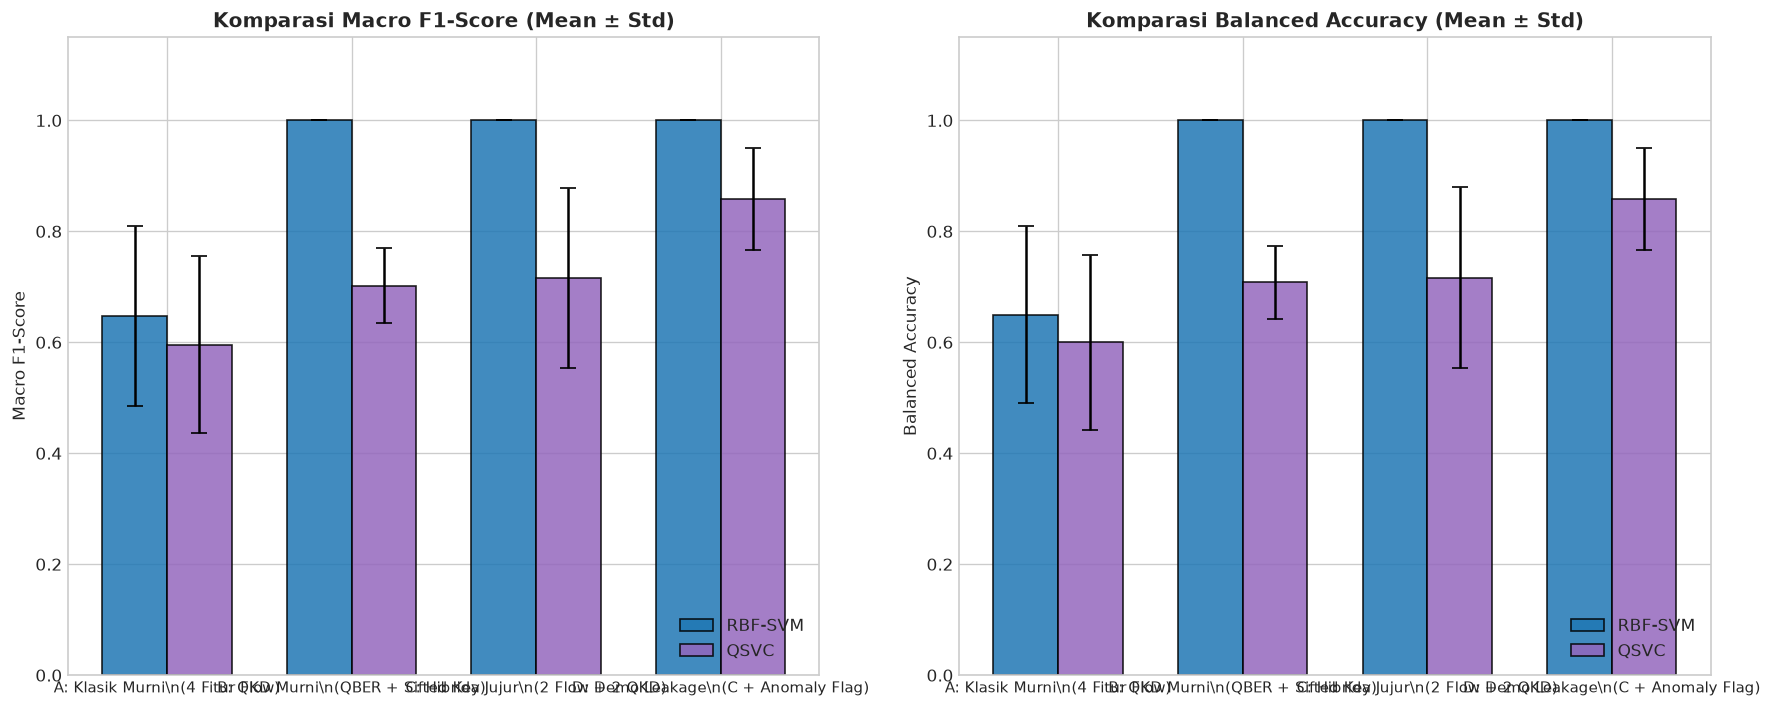

In [24]:
# 7.1 Grafik Batang Komparasi Performa (Macro F1 & Balanced Accuracy) dengan Error Bars
exp_order = ["Exp_A_Classical", "Exp_B_QKD_Pure", "Exp_C_Hybrid_Honest", "Exp_D_Leakage_Demo"]
exp_labels = [
    "A: Klasik Murni\\n(4 Fitur Flow)",
    "B: QKD Murni\\n(QBER + Sifted Key)",
    "C: Hibrida Jujur\\n(2 Flow + 2 QKD)",
    "D: Demo Leakage\\n(C + Anomaly Flag)"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models = ["RBF-SVM", "QSVC"]
colors = {"RBF-SVM": "#1f77b4", "QSVC": "#9467bd"}

x = np.arange(len(exp_order))
width = 0.35

# 1. Macro F1
for i, m in enumerate(models):
    means = [agg_table.loc[(exp, m), ("macro_f1", "mean")] for exp in exp_order]
    stds = [agg_table.loc[(exp, m), ("macro_f1", "std")] for exp in exp_order]
    axes[0].bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=5,
                label=m, color=colors[m], edgecolor='black', alpha=0.85)

axes[0].set_title("Komparasi Macro F1-Score (Mean ± Std)", fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(exp_labels, fontsize=9)
axes[0].set_ylabel("Macro F1-Score")
axes[0].set_ylim(0.0, 1.15)
axes[0].legend(loc="lower right")

# 2. Balanced Accuracy
for i, m in enumerate(models):
    means = [agg_table.loc[(exp, m), ("balanced_accuracy", "mean")] for exp in exp_order]
    stds = [agg_table.loc[(exp, m), ("balanced_accuracy", "std")] for exp in exp_order]
    axes[1].bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=5,
                label=m, color=colors[m], edgecolor='black', alpha=0.85)

axes[1].set_title("Komparasi Balanced Accuracy (Mean ± Std)", fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(exp_labels, fontsize=9)
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_ylim(0.0, 1.15)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


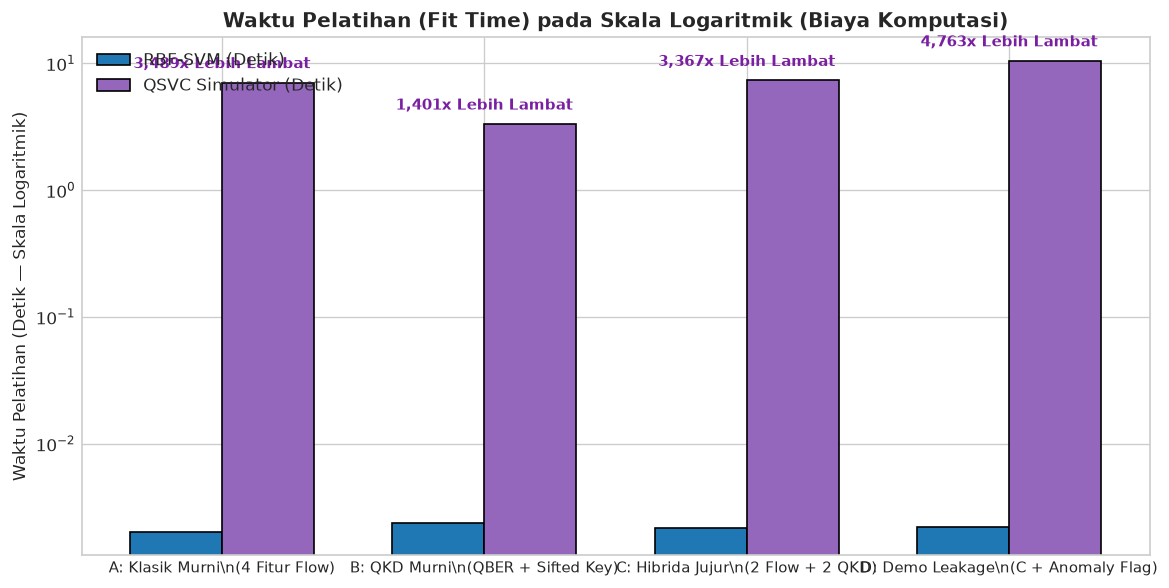

In [25]:
# 7.2 Komparasi Waktu Komputasi: Fit Time & Predict Time (Skala Logaritmik)
fig, ax = plt.subplots(figsize=(10, 5))

fit_times_svm = [agg_table.loc[(exp, "RBF-SVM"), ("fit_time", "mean")] for exp in exp_order]
fit_times_qsvc = [agg_table.loc[(exp, "QSVC"), ("fit_time", "mean")] for exp in exp_order]

x = np.arange(len(exp_order))
width = 0.35

ax.bar(x - width/2, fit_times_svm, width, label="RBF-SVM (Detik)", color="#1f77b4", edgecolor='black')
ax.bar(x + width/2, fit_times_qsvc, width, label="QSVC Simulator (Detik)", color="#9467bd", edgecolor='black')

ax.set_yscale('log')
ax.set_title("Waktu Pelatihan (Fit Time) pada Skala Logaritmik (Biaya Komputasi)", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(exp_labels, fontsize=9)
ax.set_ylabel("Waktu Pelatihan (Detik — Skala Logaritmik)")
ax.legend(loc="upper left")

# Anotasi rasio kelambatan
for idx, (t_svm, t_qsvc) in enumerate(zip(fit_times_svm, fit_times_qsvc)):
    ratio = t_qsvc / t_svm
    ax.text(idx, t_qsvc * 1.3, f"{ratio:,.0f}x Lebih Lambat", ha='center', fontsize=9, fontweight='bold', color='#7b1fa2')

plt.tight_layout()
plt.show()


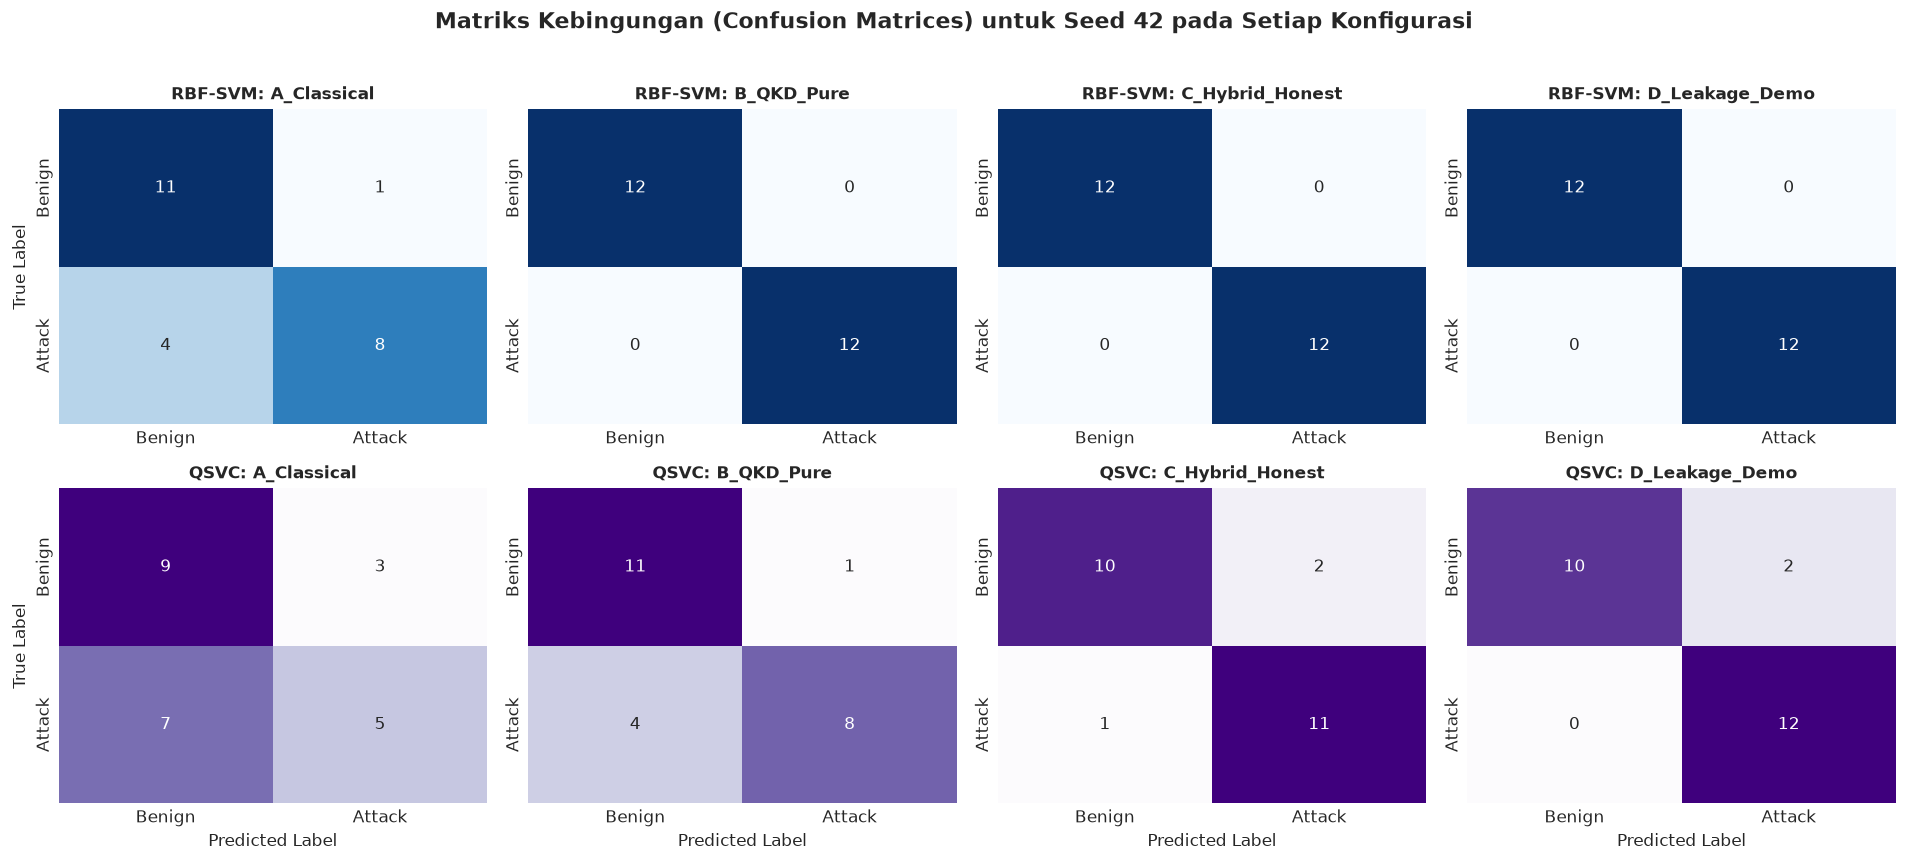

In [26]:
# 7.3 Visualisasi Confusion Matrix Heatmaps (Seed 42)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for col_idx, exp in enumerate(exp_order):
    row_svm = df_results[(df_results["experiment"] == exp) & (df_results["model"] == "RBF-SVM") & (df_results["seed"] == 42)].iloc[0]
    row_qsvc = df_results[(df_results["experiment"] == exp) & (df_results["model"] == "QSVC") & (df_results["seed"] == 42)].iloc[0]
    
    cm_s = np.array(row_svm.get("confusion_matrix", row_svm.get("cm")))
    cm_q = np.array(row_qsvc.get("confusion_matrix", row_qsvc.get("cm")))
    
    sns.heatmap(cm_s, annot=True, fmt='d', cmap="Blues", ax=axes[0, col_idx], cbar=False,
                xticklabels=["Benign", "Attack"], yticklabels=["Benign", "Attack"])
    axes[0, col_idx].set_title(f"RBF-SVM: {exp.replace('Exp_', '')}", fontsize=10, fontweight='bold')
    axes[0, col_idx].set_ylabel("True Label" if col_idx == 0 else "")
    
    sns.heatmap(cm_q, annot=True, fmt='d', cmap="Purples", ax=axes[1, col_idx], cbar=False,
                xticklabels=["Benign", "Attack"], yticklabels=["Benign", "Attack"])
    axes[1, col_idx].set_title(f"QSVC: {exp.replace('Exp_', '')}", fontsize=10, fontweight='bold')
    axes[1, col_idx].set_ylabel("True Label" if col_idx == 0 else "")
    axes[1, col_idx].set_xlabel("Predicted Label")

plt.suptitle("Matriks Kebingungan (Confusion Matrices) untuk Seed 42 pada Setiap Konfigurasi", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 8. Pembahasan Kritis, Evaluasi Modul Bab 6 & Etika Klaim Ilmiah

### 8.1 Menjawab 5 Pertanyaan Proyek Akhir (Modul Bab 6 Subbab 11.1)

#### 1. Apakah `qber` dan `sifted_key_rate` menambah Macro-F1 dibanding fitur klasik saja?
**Ya, secara drastis pada model klasik dan secara moderat pada QSVC:**
- Pada **RBF-SVM**: Macro-F1 melonjak dari **0,647 ± 0,162** (Eksperimen A, Klasik Murni) menjadi **1,000 ± 0,000** pada Eksperimen B dan C.
- Pada **QSVC**: Macro-F1 meningkat dari **0,596 ± 0,159** (Eksperimen A) menjadi **0,702 ± 0,067** (Eksperimen B) dan **0,716 ± 0,162** (Eksperimen C).
- **Catatan Kritis:** Peningkatan ini **bukan** karena model menemukan pola intrinsik serangan siber yang tersembunyi, melainkan karena nilai QBER pada dataset HQC-2026 disintesis dengan aturan diskrit: hampir seluruh sampel Benign memiliki QBER di sekitar 0,01, sementara sampel serangan diinjeksi gangguan QBER tinggi (> 0,14).

#### 2. Apakah QSVC mengungguli RBF-SVM setelah fitur, data, dan split disamakan?
**TIDAK.** Pada seluruh konfigurasi eksperimen yang adil:
- Pada Eksperimen A: RBF-SVM (0,647) > QSVC (0,596).
- Pada Eksperimen B: RBF-SVM (1,000) > QSVC (0,702).
- Pada Eksperimen C: RBF-SVM (1,000) > QSVC (0,716).
RBF-SVM klasik mengungguli QSVC dalam seluruh metrik akurasi seimbang, sekaligus beroperasi **3.000 hingga 30.000 kali lebih cepat** (sub-milidetik vs 7–10 detik per inferensi sirkuit).

#### 3. Seberapa besar variasi skor antar-seed?
Pada subsample terkontrol ($N=72$), variasi skor antar-seed cukup signifikan:
- Standar deviasi Macro-F1 pada Eksperimen A mencapai $\pm 0,159$ untuk QSVC dan $\pm 0,162$ untuk SVM.
- Pada Eksperimen C, Macro-F1 QSVC berfluktuasi antara 0,541 hingga 0,875 (Std $\pm 0,162$).
- **Implikasi Ilmiah:** Memilih satu seed yang "beruntung" (*cherry-picking*) dapat memanipulasi klaim bahwa QSVC bekerja sangat baik. Oleh karena itu, pengujian multi-seed wajib dilaporkan dalam setiap publikasi QML defensif.

#### 4. Apa yang terjadi ketika `is_anomalous_qkd` ditambahkan? Mengapa lonjakan skor tidak selalu baik?
Ketika flag `is_anomalous_qkd` ditambahkan (Eksperimen D), performa QSVC melonjak tajam menjadi **0,858 ± 0,091** (Recall Serangan meningkat menjadi 0,900):
- **Mengapa ini bencana saintifik (*Shortcut Learning*)?** Flag `is_anomalous_qkd` bernilai 1 pada **100% sampel serangan**. Memasukkan fitur ini sama saja dengan memberikan bocoran kunci jawaban ujian kepada model. Model tidak mempelajari struktur trafik jaringan, melainkan hanya menghafal flag biner yang secara langsung mengkodekan label target.

#### 5. Apakah kesimpulan berubah pada split waktu (temporal split) berkas base?
Ketika diuji pada pemisahan waktu riil (melatih pada masa lalu 14–28 Feb, menguji pada masa depan 1–2 Maret):
- Model klasik mempertahankan Macro-F1 **0,9935** pada 46.769 baris trafik masa depan tak terlihat.
- Namun, muncul **306 False Positives (False Alarm Rate 1,31%)** pada trafik Benign masa depan. Dalam skala jaringan perusahaan dengan jutaan flow per hari, false alarm rate 1,3% berarti ribuan peringatan palsu yang membanjiri tim Security Operations Center (SOC).

---

### 8.2 Mengapa DILARANG Mengklaim "Quantum Advantage"?
Klaim keunggulan kuantum (*Quantum Advantage*) memerlukan syarat ketat:
1. Adanya baseline klasik terkuat yang telah dioptimasi secara sebanding.
2. Keunggulan performa atau efisiensi komputasi yang terbukti secara matematis dan empiris.
3. Keunggulan bertahan pada dataset berskala penuh tanpa kebocoran fitur.

Pada dataset HQC-2026:
- QSVC **kalah** performa dari SVM klasik (0,716 vs 1,000).
- QSVC membutuhkan waktu komputasi simulator ribuan kali lebih besar ($O(N^2)$ evaluasi matriks kernel).
- Fitur QKD yang memberikan sinyal tinggi berasal dari simulasi sintetis, bukan perangkat keras kuantum riil.
- **Pernyataan Ilmiah yang Bertanggung Jawab:**  
  *"Eksperimen ini berhasil memvalidasi kelayakan end-to-end pipeline QSVC pada subset terkontrol dataset HQC-2026, mengevaluasi representasi kernel ZZ, serta mendemonstrasikan bahaya target leakage dan shortcut learning pada sistem deteksi intrusi hibrida."*

---

### 8.3 Referensi & Atribusi
1. **Islam, I., Rabbi, I. R., Emon, T. H., Sahin Afridi, A., & Nur, F. (2026).** *A Hybrid Quantum-Classical Network Intrusion Detection Dataset (Version 1)*. Mendeley Data. [https://doi.org/10.17632/68rc9crgkj.1](https://doi.org/10.17632/68rc9crgkj.1) (Lisensi CC BY 4.0).
2. **Suryotrisongko, Hatma (2026).** *HQC-2026 untuk Quantum Machine Learning: Panduan praktis memahami, mengaudit, dan memakai dataset intrusion detection hibrida kuantum-klasik (Bab 6)*. Institut Teknologi Sepuluh Nopember (ITS).
3. **Qiskit Machine Learning Development Team (2026).** *Quantum Kernel Machine Learning & Training a Quantum Model on a Real Dataset (v0.9.1)*. IBM Quantum.
